<a href="https://colab.research.google.com/github/gerardagustina/breast-cancer-survival-analysis/blob/main/notebooks/03_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Models: Cox proportional hazards and machine learning survival models
Cox PH (interpretable baseline), proportional hazards check, Random Survival Forest and Gradient Boosting.

In [1]:
!pip install -q lifelines scikit-survival

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines.datasets import load_gbsg2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
FEATURES = ["horTh", "age", "menostat", "tsize", "pnodes",
            "progrec", "estrec", "tgrade_II", "tgrade_III"]
NUM_COLS = ["age", "tsize", "pnodes", "progrec", "estrec"]


def prepare_data(seed=42, test_size=0.2):
    """Load GBSG2 and return a stratified, standardised train/test split."""
    df = load_gbsg2().rename(columns={"cens": "event"})

    df["horTh"] = (df["horTh"] == "yes").astype(int)
    df["menostat"] = (df["menostat"] == "Post").astype(int)
    df = pd.get_dummies(df, columns=["tgrade"], drop_first=True, dtype=int)

    for col in ["pnodes", "progrec", "estrec"]:
        df[col] = np.log1p(df[col])

    X = df[FEATURES]
    y = df[["time", "event"]]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y["event"], random_state=seed
    )

    X_train, X_test = X_train.copy(), X_test.copy()
    scaler = StandardScaler()
    X_train[NUM_COLS] = scaler.fit_transform(X_train[NUM_COLS])
    X_test[NUM_COLS] = scaler.transform(X_test[NUM_COLS])

    return X_train, X_test, y_train, y_test, scaler

In [3]:
X_train, X_test, y_train, y_test, scaler = prepare_data(seed=SEED)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print(f"Event rate train: {y_train['event'].mean():.3f} | test: {y_test['event'].mean():.3f}")

X_train: (548, 9) | X_test: (138, 9)
Event rate train: 0.436 | test: 0.435


In [4]:
from lifelines import CoxPHFitter

train_df = pd.concat([X_train, y_train], axis=1)

cph = CoxPHFitter()
cph.fit(train_df, duration_col="time", event_col="event")

hr_table = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
hr_table.columns = ["HR", "HR lower 95%", "HR upper 95%", "p"]
hr_table.round(3)

,HR,HR lower 95%,HR upper 95%,p
covariate,,,,
horTh,0.675,0.509,0.895,0.006
age,0.865,0.703,1.063,0.168
menostat,1.277,0.845,1.930,0.246
tsize,1.004,0.886,1.137,0.952
pnodes,1.623,1.423,1.852,0.000
progrec,0.688,0.580,0.817,0.000
estrec,1.090,0.921,1.291,0.316
tgrade_II,1.844,1.035,3.285,0.038
tgrade_III,1.890,1.006,3.548,0.048


In [5]:
rule = pd.DataFrame({"mean": scaler.mean_, "std": scaler.scale_}, index=NUM_COLS)
rule["exp(std)"] = np.exp(rule["std"])
rule.round(2)

,mean,std,exp(std)
age,52.85,10.23,27844.74
tsize,29.47,14.23,1509761.41
pnodes,1.51,0.72,2.05
progrec,3.31,1.95,7.02
estrec,3.35,1.85,6.39


In [6]:
from lifelines.statistics import proportional_hazard_test

ph_test = proportional_hazard_test(cph, train_df, time_transform="rank")
ph_test.summary[["test_statistic", "p"]].round(3)

,test_statistic,p
age,1.791,0.181
estrec,2.519,0.112
horTh,0.288,0.592
menostat,0.261,0.609
pnodes,2.481,0.115
progrec,0.101,0.751
tgrade_II,0.414,0.520
tgrade_III,2.632,0.105
tsize,1.316,0.251


In [7]:
from sksurv.util import Surv

y_train_s = Surv.from_arrays(event=y_train["event"].astype(bool), time=y_train["time"])
y_test_s = Surv.from_arrays(event=y_test["event"].astype(bool), time=y_test["time"])

print(y_train_s[:5])
print(y_train_s.dtype)

[(False, 1427.) ( True,  370.) ( True,  308.) (False,  722.)
 (False, 1212.)]
[('event', '?'), ('time', '<f8')]


In [8]:
from sksurv.ensemble import RandomSurvivalForest

rsf = RandomSurvivalForest(
    n_estimators=500,
    min_samples_leaf=15,
    max_features="sqrt",
    n_jobs=-1,
    random_state=SEED,
)
rsf.fit(X_train, y_train_s)

print("Trees trained:", len(rsf.estimators_))

Trees trained: 500


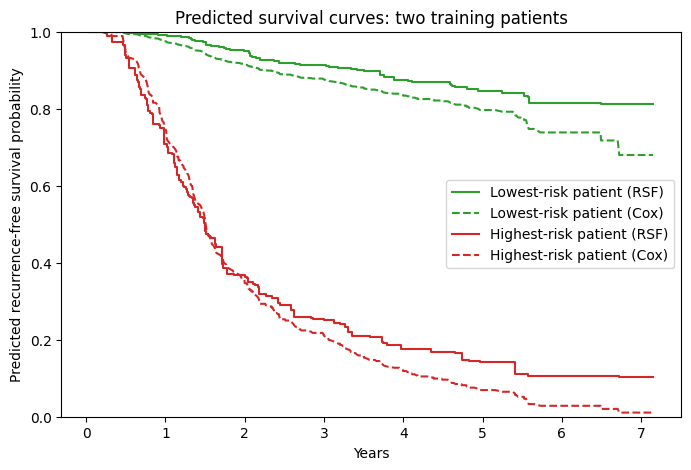

,horTh,age,menostat,tsize,pnodes,progrec,estrec,tgrade_II,tgrade_III
384,1,-0.57,0,-1.23,-1.14,0.72,-0.35,1,0
440,0,0.60,1,-0.17,2.12,-0.52,-1.21,0,1


In [9]:
risk_rsf = rsf.predict(X_train)
idx_low = np.argmin(risk_rsf)
idx_high = np.argmax(risk_rsf)
patients = X_train.iloc[[idx_low, idx_high]]

surv_rsf = rsf.predict_survival_function(patients)
surv_cox = cph.predict_survival_function(patients)

fig, ax = plt.subplots(figsize=(8, 5))
for i, (label, color) in enumerate([("Lowest-risk patient", "tab:green"),
                                    ("Highest-risk patient", "tab:red")]):
    ax.step(surv_rsf[i].x / 365.25, surv_rsf[i].y, where="post",
            color=color, label=f"{label} (RSF)")
    ax.plot(surv_cox.index / 365.25, surv_cox.iloc[:, i],
            color=color, linestyle="--", label=f"{label} (Cox)")

ax.set_xlabel("Years")
ax.set_ylabel("Predicted recurrence-free survival probability")
ax.set_title("Predicted survival curves: two training patients")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

patients.round(2)

In [10]:
from sksurv.ensemble import GradientBoostingSurvivalAnalysis

gbs = GradientBoostingSurvivalAnalysis(
    loss="coxph",
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    subsample=0.8,
    random_state=SEED,
)
gbs.fit(X_train, y_train_s)

print("Trees trained:", len(gbs.estimators_))

Trees trained: 200


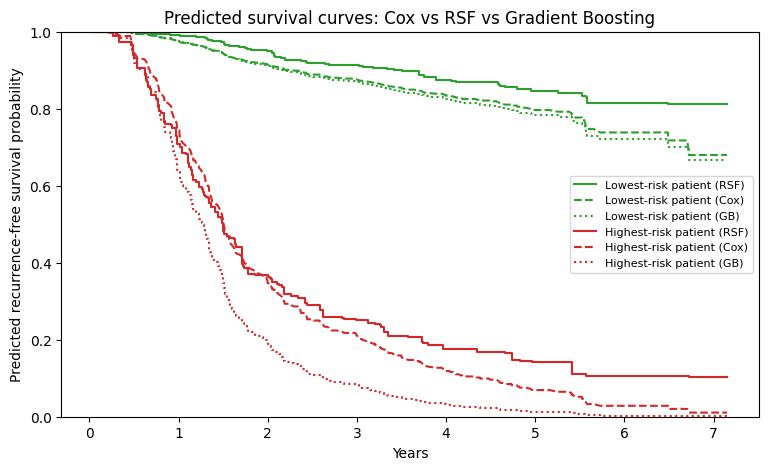

In [11]:
surv_gbs = gbs.predict_survival_function(patients)

fig, ax = plt.subplots(figsize=(9, 5))
for i, (label, color) in enumerate([("Lowest-risk patient", "tab:green"),
                                    ("Highest-risk patient", "tab:red")]):
    ax.step(surv_rsf[i].x / 365.25, surv_rsf[i].y, where="post",
            color=color, label=f"{label} (RSF)")
    ax.plot(surv_cox.index / 365.25, surv_cox.iloc[:, i],
            color=color, linestyle="--", label=f"{label} (Cox)")
    ax.step(surv_gbs[i].x / 365.25, surv_gbs[i].y, where="post",
            color=color, linestyle=":", label=f"{label} (GB)")

ax.set_xlabel("Years")
ax.set_ylabel("Predicted recurrence-free survival probability")
ax.set_title("Predicted survival curves: Cox vs RSF vs Gradient Boosting")
ax.set_ylim(0, 1)
ax.legend(fontsize=8)
plt.show()